Machine Learning Workflow
Objective
Develop and compare multiple machine learning models to predict customer churn and identify the best-performing solution.

Workflow Overview
The machine learning workflow consists of the following stages:

Data Collection
Data Understanding
Exploratory Data Analysis
Data Cleaning
Feature Engineering
Model Development
Model Evaluation
Hyperparameter Tuning
Pipeline Construction
Final Model Selection
Feature Engineering Workflow
The following preprocessing steps will be included:

Missing Values
Numerical variables: Mean imputation
Categorical variables: Most frequent value imputation
Encoding
One-Hot Encoding for categorical features
Scaling
StandardScaler for numerical variables
Train-Test Split
Training Set: 80%
Test Set: 20%
Candidate Models
The following models will be evaluated:

Baseline Models
Logistic Regression
Tree-Based Models
Decision Tree
Random Forest
Boosting Models
Gradient Boosting
Optional Models
XGBoost
LightGBM
Model Evaluation Metrics
Performance will be measured using:

Accuracy
Precision
Recall
F1 Score
ROC-AUC
Hyperparameter Tuning
The best-performing models will be optimized using:

GridSearchCV
Cross Validation
Final Output
The final deliverable will be a complete machine learning pipeline that:

Accepts raw customer data
Performs preprocessing automatically
Generates churn predictions
Can be saved and reused in production

In [50]:
from sklearn.model_selection import train_test_split

print("Machine Learning Workflow Defined")


Machine Learning Workflow Defined


Load Required Libraries
The baseline model will use Logistic Regression as the first machine learning algorithm.

Additional libraries are required for:

Model training
Prediction generation
Performance evaluation
Classification reporting

In [51]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix)

print("Libraries Loaded")

Libraries Loaded


Load and Prepare Dataset
The same preprocessing steps developed during the feature engineering phase will be applied so that the baseline model receives clean and properly transformed data.

In [52]:
df = pd.read_csv("../data/raw/Telco-Customer-Churn.csv")

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

df = df.dropna(subset=["TotalCharges"])

df = df.drop("customerID", axis=1)

df.shape

(7032, 20)

Create Feature Matrix and Target Variable
The target variable is separated from the predictor variables before model training.

In [53]:
X = df.drop("Churn", axis=1)

y = df["Churn"]

print(X.shape)
print(y.shape)

(7032, 19)
(7032,)


Create Training and Testing Sets
The dataset is divided into training and testing subsets using an 80/20 split.

Stratification is applied to preserve the original churn distribution.

In [54]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

print(X_train.shape)
print(X_test.shape)


(5625, 19)
(1407, 19)


Identify Feature Types
Different preprocessing techniques are required for numerical and categorical variables.

The next step is to identify each feature type so that the appropriate transformations can be applied during preprocessing.

This approach ensures that:

Numerical variables are properly scaled
Categorical variables are properly encoded
The preprocessing workflow remains reproducible and reusable

In [55]:
numerical_features = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]

categorical_features = [col for col in X.columns if col not in numerical_features]

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


Build the Preprocessing Pipeline
Before training a machine learning model, the data must be transformed into a format that algorithms can understand.

Numerical Features
Numerical variables will be standardised using:

StandardScaler
Categorical Features
Categorical variables will be transformed using:

OneHotEncoder
These transformations will be combined into a single reusable preprocessing pipeline.

In [56]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [57]:
numerical_transformer = Pipeline(steps=[("scaler", StandardScaler())])

categorical_transformer = Pipeline(steps=[("onehot", OneHotEncoder(handle_unknown="ignore"))]
)

In [58]:
preprocessor = ColumnTransformer(transformers=[("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)])

Train Logistic Regression Baseline Model
Logistic Regression is selected as the baseline model because:

It is commonly used for binary classification
It is easy to interpret
It provides a strong benchmark for comparison with more complex algorithms
The model will be combined with the preprocessing pipeline to create a complete machine learning workflow.

In [59]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", LogisticRegression(random_state=42))])

logistic_model.fit(X_train, y_train)

print("Baseline Logistic Regression Model Trained")

Baseline Logistic Regression Model Trained


Generate Predictions
The trained model will now generate predictions on the testing dataset.

These predictions will be used to evaluate model performance.

In [60]:
y_pred = logistic_model.predict(X_test)

y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Predictions Generated")

Predictions Generated


Model Evaluation
The baseline Logistic Regression model will now be evaluated using several classification metrics.

Evaluation Metrics
Accuracy
Precision
Recall
F1 Score
ROC-AUC
These metrics provide a comprehensive assessment of model performance and establish a benchmark for future model comparisons.

In [61]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, pos_label="Yes")

recall = recall_score(y_test, y_pred, pos_label="Yes")

f1 = f1_score(y_test, y_pred, pos_label="Yes")

roc_auc = roc_auc_score((y_test == "Yes").astype(int), y_prob)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Accuracy:  0.8038
Precision: 0.6485
Recall:    0.5722
F1 Score:  0.6080
ROC-AUC:   0.8359


Classification Report
The classification report provides a detailed breakdown of precision, recall, and F1-score for each class.

This helps identify how effectively the model predicts churned and retained customers.

In [62]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1033
         Yes       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



Confusion Matrix
The confusion matrix summarises prediction outcomes and helps identify:

Correct predictions
False positives
False negatives
This information is particularly useful when evaluating customer churn models because incorrectly classifying churning customers can have significant business implications.

In [63]:
conf_matrix = confusion_matrix(y_test, y_pred)

conf_matrix

array([[917, 116],
       [160, 214]])

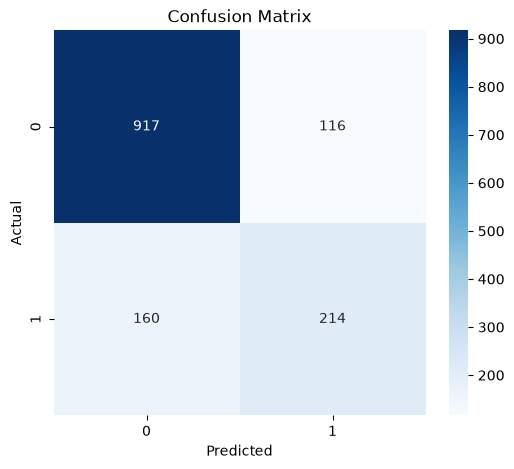

In [64]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Findings
The Logistic Regression model provided a strong baseline for customer churn prediction.

Performance Summary
Metric	Score
Accuracy	0.8038
Precision	0.6485
Recall	0.5722
F1 Score	0.6080
ROC-AUC	0.8359
Key Observations
The model correctly classified approximately 80.4% of customer records.

The ROC-AUC score of 0.8359 indicates good discriminative ability and suggests that the model is effective at distinguishing between customers who churn and those who remain.

Precision exceeded recall, indicating that when the model predicts customer churn, it is often correct. However, some customers who eventually churn are not being identified.

Confusion Matrix Analysis
The model produced:

917 True Negatives
214 True Positives
116 False Positives
160 False Negatives
The false negatives are particularly important because these represent customers who churned but were predicted to remain with the company.

Business Interpretation
From a customer retention perspective, false negatives represent missed retention opportunities.

Although the model performs reasonably well, improving recall may help the business identify a greater proportion of customers at risk of leaving.

Baseline Assessment
The Logistic Regression model establishes a strong baseline and demonstrates that meaningful churn prediction is possible using the available customer information.

More advanced models may improve performance by capturing non-linear relationships and complex interactions within the data.

Summary and Key Findings
The baseline modelling phase successfully produced the first predictive model for customer churn.

Model Overview
A Logistic Regression classifier was selected as the baseline model because it:

Is widely used for binary classification problems
Provides interpretable results
Establishes a benchmark for comparison with more complex algorithms
Data Preparation
The model was trained using:

Standardised numerical features
One-Hot Encoded categorical features
An automated preprocessing pipeline
An 80/20 train-test split
Baseline Performance
Metric	Score
Accuracy	0.8038
Precision	0.6485
Recall	0.5722
F1 Score	0.6080
ROC-AUC	0.8359
Key Insights
The model demonstrated strong overall performance and successfully identified meaningful patterns associated with customer churn.

The strongest results were observed in:

Overall accuracy
ROC-AUC performance
However, the model still failed to identify a portion of churning customers, suggesting that further improvements may be possible with more sophisticated algorithms.

Strengths
Simple and interpretable
Strong baseline accuracy
Good predictive power
Fully integrated preprocessing pipeline
Limitations
Limited ability to capture complex non-linear relationships
Moderate recall performance
Misses some churning customers
Next Steps
The next notebook will compare multiple machine learning models, including:

Decision Tree
Random Forest
Gradient Boosting
The objective will be to identify the best-performing model for customer churn prediction and establish a candidate for hyperparameter tuning and final deployment.